<a href="https://colab.research.google.com/github/caiyunkai404602-jpg/DSAA2011-TaskA-RainAustralia/blob/main/Task4_partA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Task 4: Prediction — Training and Testing (Part A: Data Splitting, Linear Models & Decision Boundary)

##
## Objective This task establishes the supervised classification baseline for predicting `RainTomorrow`.
##In Part A, we partition the preprocessed dataset into training (70%) and testing (30%) sets, train two linear model classes covered in lectures (**Logistic Regression** and **Ridge Linear Classifier**), evaluate their performance individually on the **training set, testing set, and entire dataset**, and visualize the **2D decision boundaries**.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Load preprocessed data from Task 1
X_PATH = "data_X_scaled_cleaned.csv"  # 若文件在同级目录，可改为 "X_scaled_cleaned.csv"
Y_PATH = "data_y_cleaned.csv"

X = pd.read_csv(X_PATH)
y = pd.read_csv(Y_PATH).iloc[:, 0]

# 2. Split dataset into 70% training set and 30% testing set (Deliverable 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Entire Dataset shape:   X = {X.shape}, y = {y.shape}")
print(f"Training Set (70%):     X_train = {X_train.shape}, Rain proportion = {y_train.mean():.4f}")
print(f"Testing Set (30%):      X_test = {X_test.shape}, Rain proportion = {y_test.mean():.4f}")

Entire Dataset shape:   X = (142193, 115), y = (142193,)
Training Set (70%):     X_train = (99535, 115), Rain proportion = 0.2242
Testing Set (30%):      X_test = (42658, 115), Rain proportion = 0.2242


In [ ]:
## Section 2 — Linear Classification Models: Training & Multi-Set Evaluation

## We select two foundational linear classifiers from Lectures L02–L04:
## 1. **Logistic Regression**: Models the posterior probability of rainfall using the sigmoid function and cross-entropy loss.
## 2. **Ridge Linear Classifier**: Applies Least Squares linear classification ($\hat{y} = \text{sign}(x^T w)$) with $L_2$ regularization.

## Following the project guidelines, each trained model is evaluated individually on the **Training Set (70%)**, **Testing Set (30%)**, and **Entire Set (100%)**, with confusion matrices plotted for each.

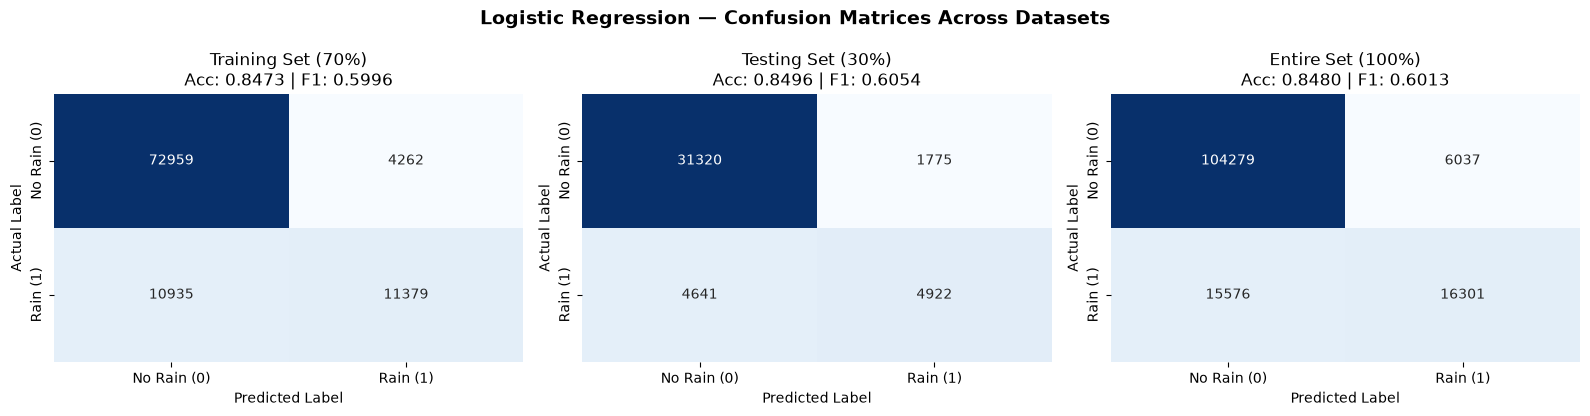

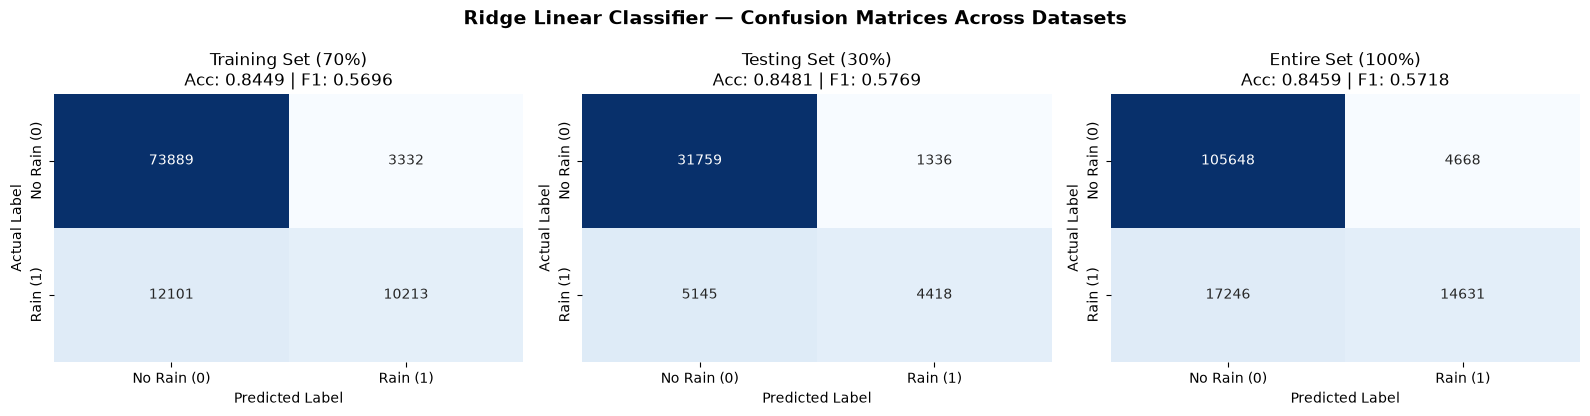

,Model,Dataset,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,Training Set (70%),0.8473,0.7275,0.5099,0.5996
1,Logistic Regression,Testing Set (30%),0.8496,0.7350,0.5147,0.6054
2,Logistic Regression,Entire Set (100%),0.8480,0.7297,0.5114,0.6013
3,Ridge Linear Classifier,Training Set (70%),0.8449,0.7540,0.4577,0.5696
4,Ridge Linear Classifier,Testing Set (30%),0.8481,0.7678,0.4620,0.5769
5,Ridge Linear Classifier,Entire Set (100%),0.8459,0.7581,0.4590,0.5718


In [3]:
# Define the 3 evaluation datasets required by Task 4 Deliverable 4
eval_datasets = {
    "Training Set (70%)": (X_train, y_train),
    "Testing Set (30%)": (X_test, y_test),
    "Entire Set (100%)": (X, y)
}

# Initialize linear models
linear_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Ridge Linear Classifier": RidgeClassifier(alpha=1.0, random_state=42)
}

partA_results = []

for model_name, model in linear_models.items():
    # Train strictly on the 70% training set
    model.fit(X_train, y_train)

    # Set up 1x3 subplots for confusion matrices
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    fig.suptitle(f"{model_name} — Confusion Matrices Across Datasets", fontsize=14, fontweight="bold")

    for idx, (set_name, (X_eval, y_eval)) in enumerate(eval_datasets.items()):
        y_pred = model.predict(X_eval)

        # Compute performance metrics
        acc = accuracy_score(y_eval, y_pred)
        prec = precision_score(y_eval, y_pred, zero_division=0)
        rec = recall_score(y_eval, y_pred, zero_division=0)
        f1 = f1_score(y_eval, y_pred, zero_division=0)

        partA_results.append({
            "Model": model_name,
            "Dataset": set_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-Score": f1
        })

        # Plot confusion matrix
        cm = confusion_matrix(y_eval, y_pred)
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
            xticklabels=["No Rain (0)", "Rain (1)"],
            yticklabels=["No Rain (0)", "Rain (1)"]
        )
        axes[idx].set_title(f"{set_name}\nAcc: {acc:.4f} | F1: {f1:.4f}")
        axes[idx].set_xlabel("Predicted Label")
        axes[idx].set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

# Display metrics table
partA_df = pd.DataFrame(partA_results)
display(partA_df.round(4))

In [ ]:
## Section 3 — Visualization of Decision Boundaries (Deliverable 3)

## Since the preprocessed dataset has 115 dimensions, we project the decision boundary onto the 2D plane formed by the two continuous weather features most strongly correlated with `RainTomorrow`: **`Humidity3pm`** ($r = 0.440$) and **`Sunshine`** ($r = -0.324$).
## We compare the linear decision boundary of **Logistic Regression** against the non-linear, axis-aligned boundary of a **Decision Tree**.

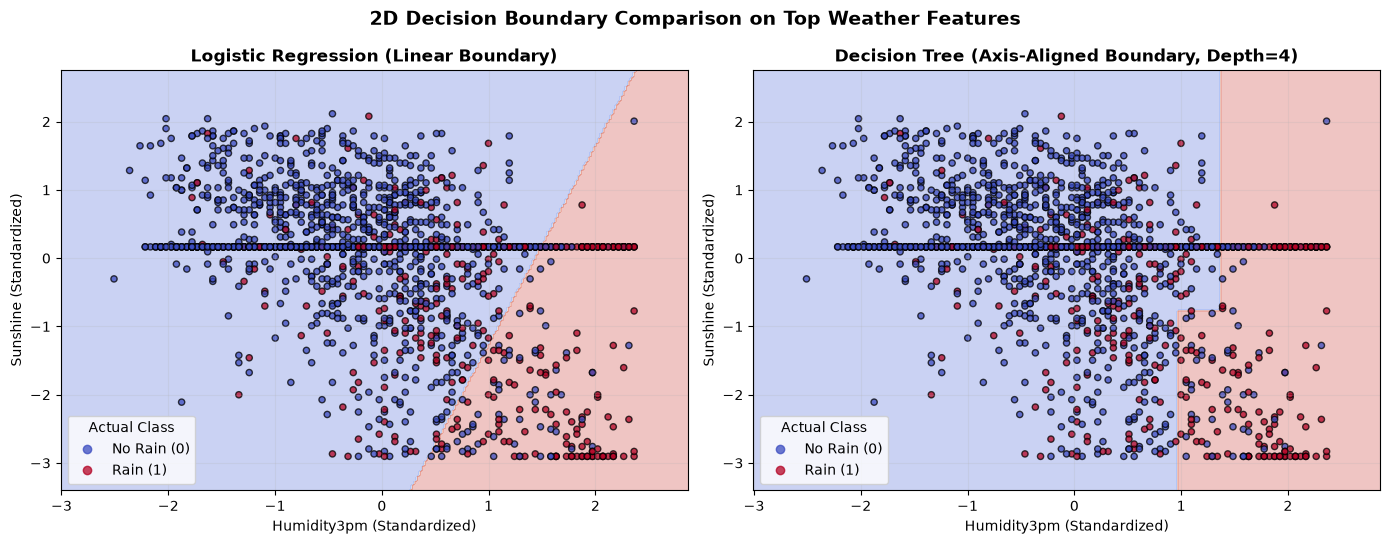

In [5]:
# Select top 2 correlated continuous features for 2D visualization
feat1, feat2 = "Humidity3pm", "Sunshine"
X_train_2d = X_train[[feat1, feat2]].values
y_train_2d = y_train.values

# Subsample 2,000 points for clear scatter visualization
np.random.seed(42)
sample_indices = np.random.choice(len(X_train_2d), size=2000, replace=False)
X_plot, y_plot = X_train_2d[sample_indices], y_train_2d[sample_indices]

# Create a dense 2D meshgrid
x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))

boundary_classifiers = [
    ("Logistic Regression (Linear Boundary)", LogisticRegression(random_state=42)),
    ("Decision Tree (Axis-Aligned Boundary, Depth=4)", DecisionTreeClassifier(max_depth=4, random_state=42))
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (title, clf) in zip(axes, boundary_classifiers):
    clf.fit(X_train_2d, y_train_2d)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Plot decision regions and data points
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    scatter = ax.scatter(
        X_plot[:, 0], X_plot[:, 1], c=y_plot, cmap="coolwarm",
        edgecolor="k", s=20, alpha=0.75
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{feat1} (Standardized)")
    ax.set_ylabel(f"{feat2} (Standardized)")
    ax.legend(handles=scatter.legend_elements()[0], labels=["No Rain (0)", "Rain (1)"], title="Actual Class")
    ax.grid(alpha=0.2)

plt.suptitle("2D Decision Boundary Comparison on Top Weather Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Task 4 — Part B: Decision Tree Models, Evaluation & Comparison

Part B reuses Part A's 70/30 split (`random_state=42`, `stratify=y`) and linear-model results (`partA_df`), so all models are compared on identical data.

In [6]:
# Sanity check: Part A variables must exist (same split: test_size=0.30, random_state=42, stratify=y)
for v in ["X", "y", "X_train", "X_test", "y_train", "y_test", "eval_datasets", "partA_df"]:
    assert v in globals(), f"Missing `{v}` - run Part A cells first."
print("Part A variables found.")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | Entire: {X.shape}")

Part A variables found.
Train: (99535, 115) | Test: (42658, 115) | Entire: (142193, 115)


In [ ]:
# Decision Tree Classifiers
# Why decision trees? They are a different model class from the linear models in Part A: they split the feature space with axis-aligned rules, can capture non-linear relationships and feature interactions, and need no feature scaling.

# Why two depths? `max_depth` controls model complexity, so comparing a shallow and a deep tree shows the bias-variance trade-off:
  # Shallow tree (max_depth=3): simple, easy to interpret, likely to underfit.
  # Deep tree (max_depth=None, grown until leaves are pure): very flexible, likely to overfit (near-perfect training score, worse test score).

# Both are trained only on the 70% training set.

Decision Tree (depth=3): actual depth = 3, leaves = 8


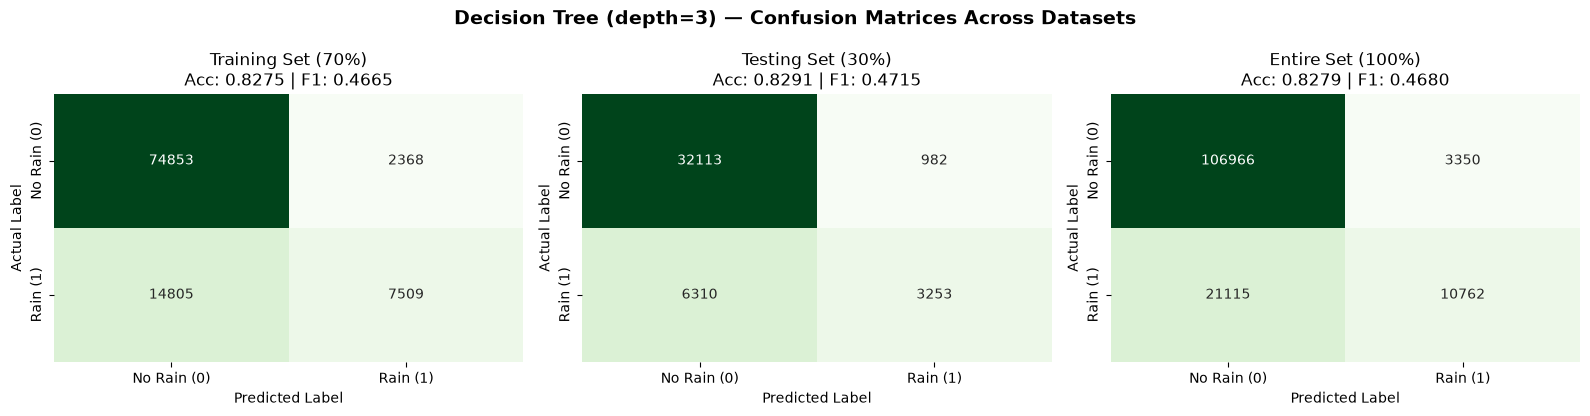

Decision Tree (depth=None): actual depth = 46, leaves = 11455


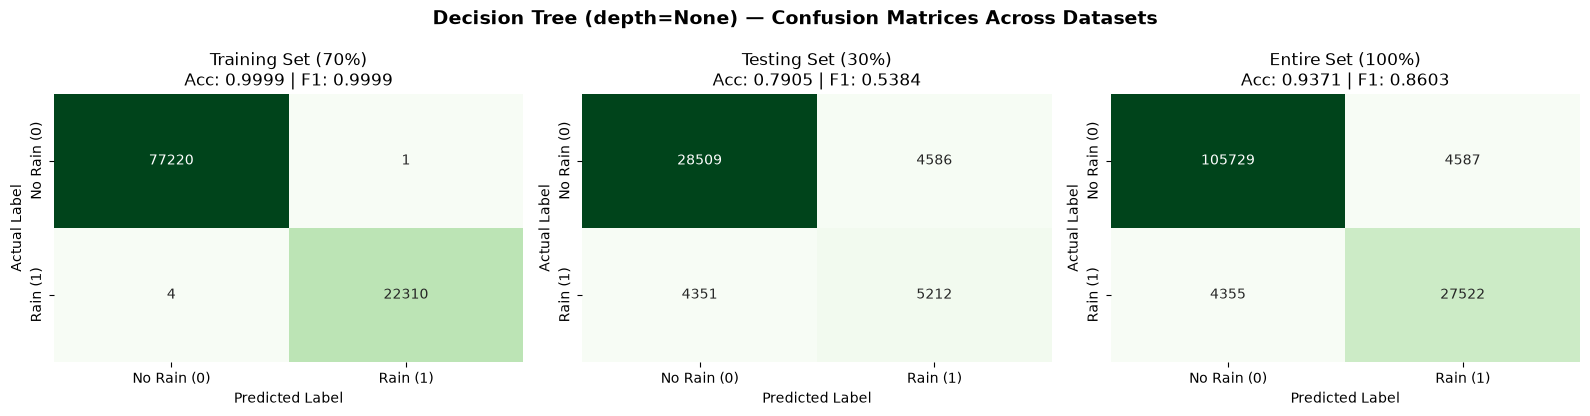


Decision Tree metrics:


,Model,Dataset,Accuracy,Precision,Recall,F1-Score
0,Decision Tree (depth=3),Training Set (70%),0.8275,0.7603,0.3365,0.4665
1,Decision Tree (depth=3),Testing Set (30%),0.8291,0.7681,0.3402,0.4715
2,Decision Tree (depth=3),Entire Set (100%),0.8279,0.7626,0.3376,0.4680
3,Decision Tree (depth=None),Training Set (70%),0.9999,1.0000,0.9998,0.9999
4,Decision Tree (depth=None),Testing Set (30%),0.7905,0.5319,0.5450,0.5384
5,Decision Tree (depth=None),Entire Set (100%),0.9371,0.8571,0.8634,0.8603


In [ ]:
# Two trees with contrasting complexity 
SHALLOW_DEPTH = 3
DEEP_DEPTH = None   # None = grow until all leaves are pure 

tree_models = {
    f"Decision Tree (depth={SHALLOW_DEPTH})": DecisionTreeClassifier(max_depth=SHALLOW_DEPTH, random_state=42),
    "Decision Tree (depth=None)": DecisionTreeClassifier(max_depth=DEEP_DEPTH, random_state=42),
}

partB_results = []

for model_name, model in tree_models.items():
    # Train strictly on the 70% training set
    model.fit(X_train, y_train)
    print(f"{model_name}: actual depth = {model.get_depth()}, leaves = {model.get_n_leaves()}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    fig.suptitle(f"{model_name} — Confusion Matrices Across Datasets", fontsize=14, fontweight="bold")

    for idx, (set_name, (X_eval, y_eval)) in enumerate(eval_datasets.items()):
        y_pred = model.predict(X_eval)

        acc = accuracy_score(y_eval, y_pred)
        prec = precision_score(y_eval, y_pred, zero_division=0)
        rec = recall_score(y_eval, y_pred, zero_division=0)
        f1 = f1_score(y_eval, y_pred, zero_division=0)

        partB_results.append({
            "Model": model_name,
            "Dataset": set_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-Score": f1
        })

        cm = confusion_matrix(y_eval, y_pred)
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[idx],
            xticklabels=["No Rain (0)", "Rain (1)"],
            yticklabels=["No Rain (0)", "Rain (1)"]
        )
        axes[idx].set_title(f"{set_name}\nAcc: {acc:.4f} | F1: {f1:.4f}")
        axes[idx].set_xlabel("Predicted Label")
        axes[idx].set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

partB_df = pd.DataFrame(partB_results)
print("\nDecision Tree metrics:")
display(partB_df.round(4))

In [ ]:
# Section 5 — Merge Linear + Tree Results (Deliverables 5 & 6)

In [8]:
# Merge Part A (linear) and Part B (tree) results into one table
all_results = pd.concat([partA_df, partB_df], ignore_index=True)

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
set_order = ["Training Set (70%)", "Testing Set (30%)", "Entire Set (100%)"]
all_results["Dataset"] = pd.Categorical(all_results["Dataset"], categories=set_order, ordered=True)
all_results = all_results.sort_values(["Model", "Dataset"]).reset_index(drop=True)

print("Full comparison table (all 4 models x 3 datasets):")
display(all_results.round(4))

# Compact view: one row per model, test-set metrics
test_table = (all_results[all_results["Dataset"] == "Testing Set (30%)"]
              .set_index("Model")[metrics].round(4))
print("\nTesting-set comparison (the fair, unseen-data view):")
display(test_table)

Full comparison table (all 4 models x 3 datasets):


,Model,Dataset,Accuracy,Precision,Recall,F1-Score
0,Decision Tree (depth=3),Training Set (70%),0.8275,0.7603,0.3365,0.4665
1,Decision Tree (depth=3),Testing Set (30%),0.8291,0.7681,0.3402,0.4715
2,Decision Tree (depth=3),Entire Set (100%),0.8279,0.7626,0.3376,0.4680
3,Decision Tree (depth=None),Training Set (70%),0.9999,1.0000,0.9998,0.9999
4,Decision Tree (depth=None),Testing Set (30%),0.7905,0.5319,0.5450,0.5384
5,Decision Tree (depth=None),Entire Set (100%),0.9371,0.8571,0.8634,0.8603
6,Logistic Regression,Training Set (70%),0.8473,0.7275,0.5099,0.5996
7,Logistic Regression,Testing Set (30%),0.8496,0.7350,0.5147,0.6054
8,Logistic Regression,Entire Set (100%),0.8480,0.7297,0.5114,0.6013
9,Ridge Linear Classifier,Training Set (70%),0.8449,0.7540,0.4577,0.5696



Testing-set comparison (the fair, unseen-data view):


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Decision Tree (depth=3),0.8291,0.7681,0.3402,0.4715
Decision Tree (depth=None),0.7905,0.5319,0.5450,0.5384
Logistic Regression,0.8496,0.7350,0.5147,0.6054
Ridge Linear Classifier,0.8481,0.7678,0.4620,0.5769


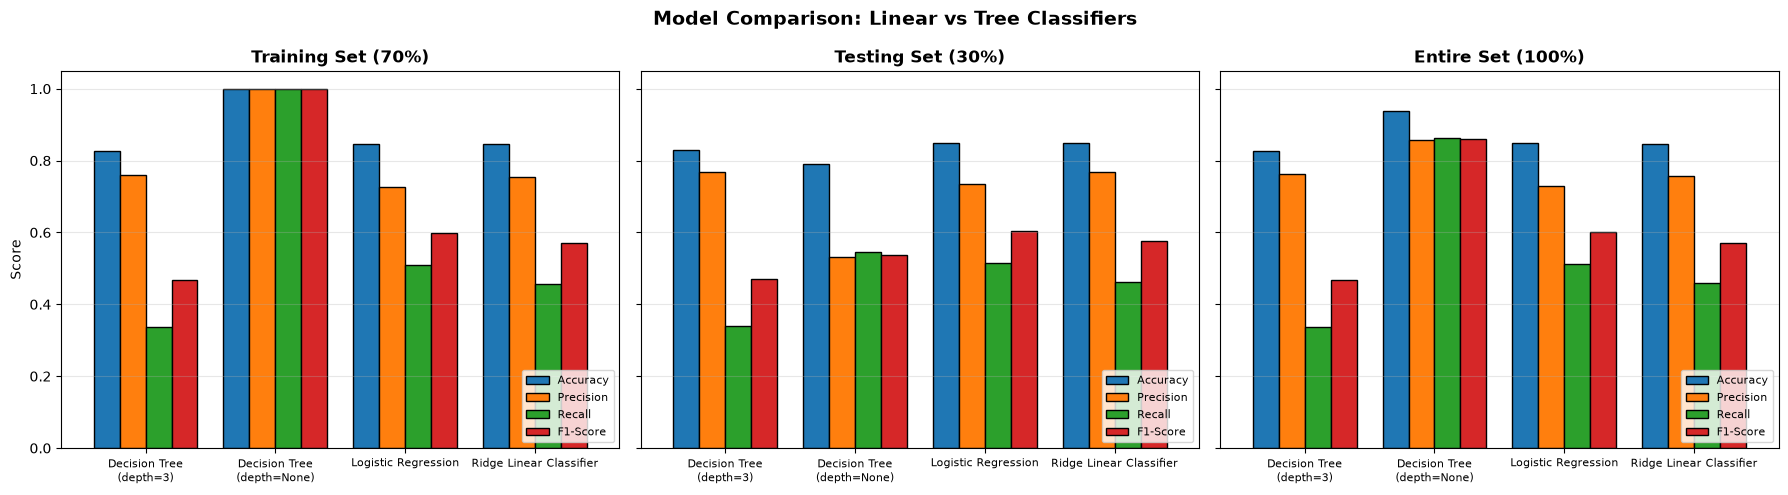

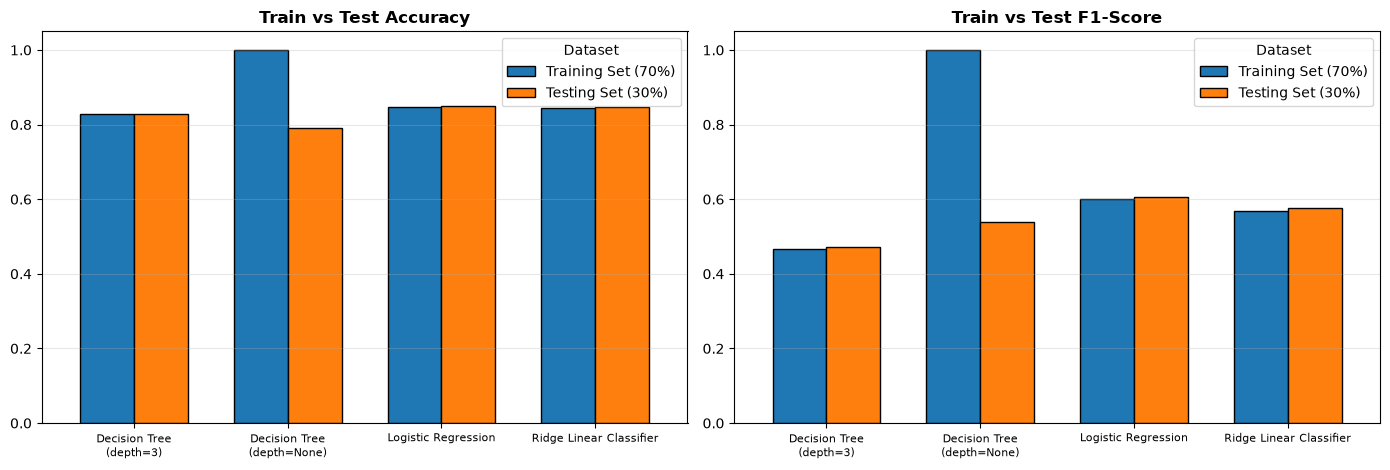

In [9]:
# Chart 1: grouped bars - each metric, per model, on each dataset
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, set_name in zip(axes, set_order):
    sub = all_results[all_results["Dataset"] == set_name].set_index("Model")[metrics]
    sub.plot(kind="bar", ax=ax, width=0.8, edgecolor="k")
    ax.set_title(set_name, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylim(0, 1.05)
    ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()], rotation=0, fontsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("Score")
plt.suptitle("Model Comparison: Linear vs Tree Classifiers", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Chart 2: overfitting check - train vs test F1 and Accuracy per model
pivot = all_results.pivot(index="Model", columns="Dataset", values=["Accuracy", "F1-Score"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, m in zip(axes, ["Accuracy", "F1-Score"]):
    pivot[m][["Training Set (70%)", "Testing Set (30%)"]].plot(kind="bar", ax=ax, edgecolor="k", width=0.7)
    ax.set_title(f"Train vs Test {m}", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylim(0, 1.05)
    ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()], rotation=0, fontsize=8)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Quantify the train-test gap and print the key facts
gap = pd.DataFrame({
    "Train Acc": pivot["Accuracy"]["Training Set (70%)"],
    "Test Acc":  pivot["Accuracy"]["Testing Set (30%)"],
    "Train F1":  pivot["F1-Score"]["Training Set (70%)"],
    "Test F1":   pivot["F1-Score"]["Testing Set (30%)"],
})
gap["Acc gap (train-test)"] = gap["Train Acc"] - gap["Test Acc"]
gap["F1 gap (train-test)"] = gap["Train F1"] - gap["Test F1"]
display(gap.round(4))

best_f1 = gap["Test F1"].idxmax()
best_acc = gap["Test Acc"].idxmax()
most_overfit = gap["F1 gap (train-test)"].idxmax()
print(f"Best test F1:        {best_f1} ({gap.loc[best_f1, 'Test F1']:.4f})")
print(f"Best test accuracy:  {best_acc} ({gap.loc[best_acc, 'Test Acc']:.4f})")
print(f"Largest F1 gap:      {most_overfit} ({gap.loc[most_overfit, 'F1 gap (train-test)']:.4f})")

,Train Acc,Test Acc,Train F1,Test F1,Acc gap (train-test),F1 gap (train-test)
Model,,,,,,
Decision Tree (depth=3),0.8275,0.8291,0.4665,0.4715,-0.0016,-0.0050
Decision Tree (depth=None),0.9999,0.7905,0.9999,0.5384,0.2095,0.4615
Logistic Regression,0.8473,0.8496,0.5996,0.6054,-0.0023,-0.0058
Ridge Linear Classifier,0.8449,0.8481,0.5696,0.5769,-0.0031,-0.0073


Best test F1:        Logistic Regression (0.6054)
Best test accuracy:  Logistic Regression (0.8496)
Largest F1 gap:      Decision Tree (depth=None) (0.4615)


## Analysis: Linear vs Tree Models

**Setup.** Only about 22.4% of days are "Rain", so a model that always predicts "No Rain" would already get about 77.6% accuracy. Accuracy alone is therefore a weak signal here, and the Rain-class **recall and F1** matter more. All comparisons below use the **testing set**, because the entire-set scores include the training data.

| Model (test set) | Accuracy | Precision | Recall | F1 | Missed rainy days (FN) | False alarms (FP) |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8496 | 0.7350 | 0.5147 | **0.6054** | 4,641 | 1,775 |
| Ridge Linear Classifier | 0.8481 | 0.7678 | 0.4620 | 0.5769 | 5,145 | 1,336 |
| Decision Tree (depth=3) | 0.8291 | 0.7681 | 0.3402 | 0.4715 | 6,310 | 982 |
| Decision Tree (depth=None) | 0.7905 | 0.5319 | 0.5450 | 0.5384 | 4,351 | 4,586 |

**Linear models.** Logistic Regression is the best model overall, with the highest test accuracy (0.8496) and F1 (0.6054). Ridge is close behind (F1 0.5769). It is slightly more cautious: it has higher precision (0.7678) but lower recall (0.4620), so it misses more rainy days. Both models score almost identically on the training, testing, and entire sets (the F1 gap is under 0.01), so they generalize well and neither overfits. Their weakness is that they still miss roughly half of the rainy days (recall about 0.46-0.51). A single linear boundary may be too simple, and the class imbalance pushes them toward predicting "No Rain".

**Shallow tree (depth=3).** It generalizes consistently (train F1 0.4665 vs test F1 0.4715), but it is **underfitting**. With only 8 leaves it is too simple, and it has the lowest recall (0.3402), missing 6,310 rainy days on the test set. Its predictions are conservative: it has the fewest false alarms (982), but its F1 is the lowest of all four models.

**Deep tree (depth=None).** This is a clear case of **overfitting**. The tree grows to depth 46 with 11,455 leaves and nearly memorizes the training set (accuracy 0.9999, F1 0.9999, with only 5 training mistakes). On unseen data it drops to accuracy 0.7905 and F1 0.5384, a train-test F1 gap of 0.46 and barely above the 77.6% always-"No Rain" baseline. Its recall is the highest (0.5450), but its precision falls to 0.5319 (4,586 false alarms), so about half of its rain predictions are wrong. Its entire-set scores (accuracy 0.9371, F1 0.8603) look impressive only because 70% of that set is data the tree has already memorized.

**Comparison and takeaway.** The ranking by test F1 is Logistic Regression (0.6054) > Ridge (0.5769) > Deep tree (0.5384) > Shallow tree (0.4715). The pattern follows the bias-variance trade-off:
- The shallow tree has **high bias** (too simple).
- The deep tree has **high variance** (too flexible).
- The linear models sit in a stable middle ground here, with low variance and moderate bias.

Which model is "best" also depends on the cost of errors. If missing a rainy day is worse than a false alarm, the deep tree's higher recall looks tempting, but its overall performance on new data is worse and less reliable.

**Possible improvements (for Task 5 and the open-ended part).** Tune `max_depth` for the tree (try something in between, such as 5-12) and use `min_samples_leaf` or `ccp_alpha` pruning, picking values with cross-validation. Use `class_weight="balanced"` or a lower decision threshold to raise recall on the Rain class. Ensemble methods such as a random forest or gradient boosting would likely beat both the single tree and the linear models, since they keep the tree's flexibility while reducing its variance.
